<a href="https://colab.research.google.com/github/valeriebarajasortiz-dev/Laboratorio-ingenieria-medica/blob/main/laboratorio_github_colab_ingenieria_medica.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laboratorio de Ingeniería Médica — GitHub + Google Colab
 **Datos:** 200 pacientes sintéticos | **Producto:** análisis, gráficos y reporte.

**Seguridad:** no introducir datos personales reales. Los umbrales de este taller son únicamente didácticos, no constituyen criterios de diagnóstico ni triaje clínico.

**Ruta:** descargar CSV → subirlo a un repositorio público de GitHub → copiar URL Raw → ejecutar las celdas → resolver retos → guardar el notebook en GitHub.

## Misión 1 — Subir la base a GitHub
1. Descargar `pacientes_simulados_200.csv`.
2. Crear un repositorio público llamado `laboratorio-ingenieria-medica` (sin datos reales).
3. En **Add file → Upload files**, subir el CSV y confirmar **Commit changes**.
4. Abrir el CSV en GitHub y pulsar **Raw**; copiar la URL que comienza por `https://raw.githubusercontent.com/`.
5. Pegar la URL en la celda siguiente.

In [1]:
import pandas as pd
URL = "https://raw.githubusercontent.com/valeriebarajasortiz-dev/Laboratorio-ingenieria-medica/refs/heads/main/pacientes_simulados_200.csv"
if not URL.startswith("https://raw.githubusercontent.com/"):
    raise ValueError("https://raw.githubusercontent.com/valeriebarajasortiz-dev/Laboratorio-ingenieria-medica/refs/heads/main/pacientes_simulados_200.csv")
df = pd.read_csv(URL)
print("Archivo conectado. Filas y columnas:", df.shape)
display(df.head())

Archivo conectado. Filas y columnas: (200, 12)


,Paciente,Edad,Sexo,Peso,Estatura,FrecuenciaCardiaca,PresionSistolica,PresionDiastolica,Saturacion,Temperatura,Glucosa,Servicio
0,P001,24,F,48.5,1.54,92,102,75,90,39.0,91,Urgencias
1,P002,61,F,97.5,1.58,107,120,78,100,37.6,163,Consulta externa
2,P003,64,M,94.8,1.71,98,155,86,100,37.3,130,Hospitalizacion
3,P004,25,F,93.2,1.49,89,98,67,97,36.2,108,Consulta externa
4,P005,69,F,77.2,1.52,88,131,69,99,36.8,115,Hospitalizacion


## Misión 2 — Comprobar la conexión
**Responde:** ¿cuántas filas y columnas hay? ¿Qué representa una fila?

In [2]:
print("Filas:", len(df))
print("Columnas:", len(df.columns))
print("Nombres de columnas:", list(df.columns))
display(df.sample(5, random_state=7))

Filas: 200
Columnas: 12
Nombres de columnas: ['Paciente', 'Edad', 'Sexo', 'Peso', 'Estatura', 'FrecuenciaCardiaca', 'PresionSistolica', 'PresionDiastolica', 'Saturacion', 'Temperatura', 'Glucosa', 'Servicio']


,Paciente,Edad,Sexo,Peso,Estatura,FrecuenciaCardiaca,PresionSistolica,PresionDiastolica,Saturacion,Temperatura,Glucosa,Servicio
86,P087,31,M,79.0,1.57,98,111,76,100,38.0,183,Observacion
120,P121,23,M,105.9,1.61,70,116,89,97,35.8,113,Urgencias
22,P023,81,M,108.0,1.57,80,160,76,99,37.0,176,Urgencias
11,P012,45,F,58.0,1.66,100,131,63,97,36.7,132,Consulta externa
195,P196,48,M,48.1,1.59,105,124,86,98,36.6,113,Hospitalizacion


## Misión 3 — Calidad de datos
**Responde:** ¿hay valores faltantes? ¿se repiten identificadores?

In [3]:
print("Datos faltantes por columna:")
print(df.isna().sum())
print("Identificadores duplicados:", df["Paciente"].duplicated().sum())
print("Tipos de dato:")
print(df.dtypes)

Datos faltantes por columna:
Paciente              0
Edad                  0
Sexo                  0
Peso                  0
Estatura              0
FrecuenciaCardiaca    0
PresionSistolica      0
PresionDiastolica     0
Saturacion            0
Temperatura           0
Glucosa               0
Servicio              0
dtype: int64
Identificadores duplicados: 0
Tipos de dato:
Paciente               object
Edad                    int64
Sexo                   object
Peso                  float64
Estatura              float64
FrecuenciaCardiaca      int64
PresionSistolica        int64
PresionDiastolica       int64
Saturacion              int64
Temperatura           float64
Glucosa                 int64
Servicio               object
dtype: object


## Misión 4 — Estadística descriptiva
**Responde:** ¿cuál es la edad promedio? ¿qué variables tienen mayor dispersión?

In [4]:
columnas = ["Edad","FrecuenciaCardiaca","Saturacion","Temperatura","Glucosa"]
display(df[columnas].describe().round(2))
print("Edad media:", round(df["Edad"].mean(),1))
print("Edad mínima:", df["Edad"].min())
print("Edad máxima:", df["Edad"].max())

,Edad,FrecuenciaCardiaca,Saturacion,Temperatura,Glucosa
count,200.00,200.00,200.00,200.00,200.00
mean,52.38,82.30,96.34,37.47,140.10
std,19.99,15.91,2.72,0.95,39.29
min,18.00,48.00,90.00,35.80,71.00
25%,35.75,71.00,95.00,36.80,107.75
50%,51.50,82.00,97.00,37.40,140.50
75%,68.00,95.00,99.00,38.20,175.25
max,88.00,121.00,100.00,39.20,204.00


Edad media: 52.4
Edad mínima: 18
Edad máxima: 88


## Misión 5 — Buscar pacientes por condiciones
**Reto:** cambia `100` por `95` y compara el número de registros. Estos valores son condiciones de programación, no decisiones clínicas.

In [19]:
criterio_fc = 95
seleccion = df[df["FrecuenciaCardiaca"] > criterio_fc]
print("Registros que superan el valor de prueba:", len(seleccion))
display(seleccion[["Paciente","Edad","FrecuenciaCardiaca"]].head(15))

Registros que superan el valor de prueba: 48


,Paciente,Edad,FrecuenciaCardiaca
1,P002,61,107
2,P003,64,98
6,P007,63,102
9,P010,86,98
11,P012,45,100
14,P015,28,97
18,P019,71,111
27,P028,84,96
32,P033,48,98
41,P042,79,103


## Misión 6 — Dos condiciones simultáneas
**Reto:** cambia el umbral de saturación de 95 a 96. Explica por qué cambia el resultado.

In [20]:
criterio_sat = 96
revision = df[(df["Saturacion"] < criterio_sat) & (df["FrecuenciaCardiaca"] > 100)]
print("Registros que cumplen ambas condiciones didácticas:",len(revision))
display(revision[["Paciente","FrecuenciaCardiaca","Saturacion"]])

Registros que cumplen ambas condiciones didácticas: 7


,Paciente,FrecuenciaCardiaca,Saturacion
46,P047,108,92
56,P057,104,95
71,P072,102,95
83,P084,109,94
85,P086,105,93
152,P153,109,94
168,P169,120,92


## Misión 7 — Crear una variable derivada
Calcula IMC y responde cuál es su promedio. No utilizarlo para diagnosticar pacientes.

In [7]:
df["IMC"] = (df["Peso"] / df["Estatura"]**2).round(2)
display(df[["Paciente","Peso","Estatura","IMC"]].head(12))
print("IMC promedio:",round(df["IMC"].mean(),2))

,Paciente,Peso,Estatura,IMC
0,P001,48.5,1.54,20.45
1,P002,97.5,1.58,39.06
2,P003,94.8,1.71,32.42
3,P004,93.2,1.49,41.98
4,P005,77.2,1.52,33.41
5,P006,100.1,1.71,34.23
6,P007,109.2,1.83,32.61
7,P008,78.7,1.78,24.84
8,P009,81.7,1.90,22.63
9,P010,56.0,1.81,17.09


IMC promedio: 28.24


## Misión 8 — Gráfico de frecuencias cardíacas
**Reto:** cambia la variable graficada por `Saturacion` y modifica el título y el eje Y.

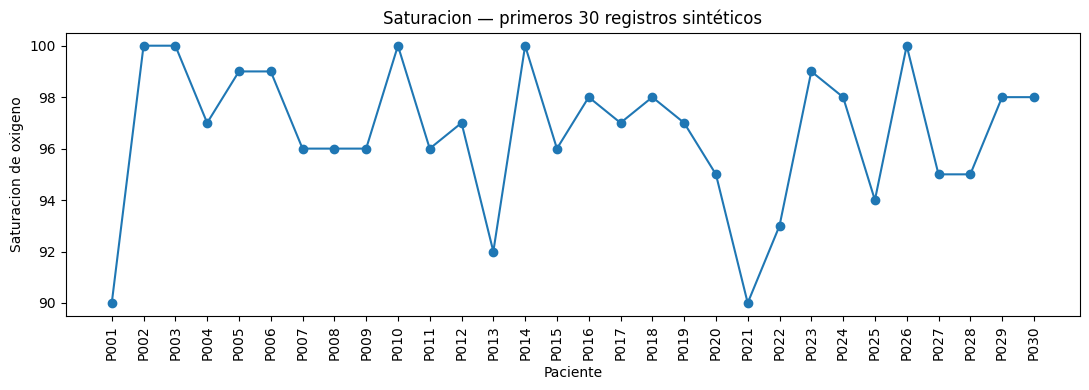

In [18]:
import matplotlib.pyplot as plt
plt.figure(figsize=(11,4))
plt.plot(df["Paciente"].head(30),df["Saturacion"].head(30),marker="o")
plt.xticks(rotation=90)
plt.title("Saturacion — primeros 30 registros sintéticos")
plt.xlabel("Paciente")
plt.ylabel("Saturacion de oxigeno")
plt.tight_layout()
plt.show()

## Misión 9 — Histogramas
**Responde:** ¿qué intervalo de edades parece más frecuente?

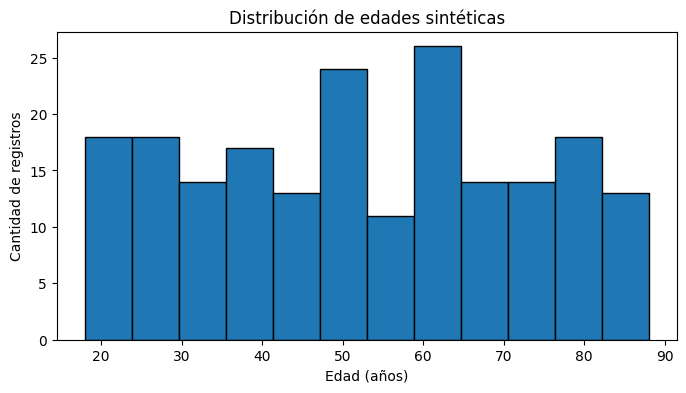

In [9]:
plt.figure(figsize=(8,4))
plt.hist(df["Edad"],bins=12,edgecolor="black")
plt.title("Distribución de edades sintéticas")
plt.xlabel("Edad (años)")
plt.ylabel("Cantidad de registros")
plt.show()

## Misión 10 — Comparación por servicios
**Responde:** ¿qué servicio tiene más registros? ¿hay diferencias en las medias?

Registros por servicio:


,Cantidad
Servicio,
Observacion,54
Hospitalizacion,51
Urgencias,50
Consulta externa,45


,Edad,FrecuenciaCardiaca,Saturacion
Servicio,,,
Consulta externa,55.4,85.1,96.4
Hospitalizacion,55.2,86.3,96.9
Observacion,48.9,79.0,95.9
Urgencias,50.6,79.3,96.1


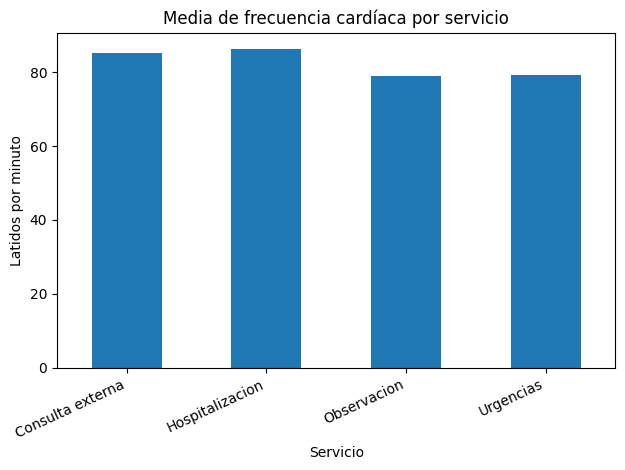

In [10]:
print("Registros por servicio:")
display(df["Servicio"].value_counts().to_frame("Cantidad"))
resumen = df.groupby("Servicio")[["Edad","FrecuenciaCardiaca","Saturacion"]].mean().round(1)
display(resumen)
resumen["FrecuenciaCardiaca"].plot(kind="bar",title="Media de frecuencia cardíaca por servicio")
plt.ylabel("Latidos por minuto")
plt.xticks(rotation=25,ha="right")
plt.tight_layout()
plt.show()

## Misión 11 — Construir un reporte automático
**Reto:** agrega una línea con el promedio de glucosa.

In [11]:
reporte = f"""REPORTE EDUCATIVO — DATOS SINTÉTICOS
Registros: {len(df)}
Edad media: {df["Edad"].mean():.1f} años
Frecuencia cardíaca media: {df["FrecuenciaCardiaca"].mean():.1f} lpm
Saturación media: {df["Saturacion"].mean():.1f}%
Registros con FC > 100 (criterio didáctico): {(df["FrecuenciaCardiaca"]>100).sum()}
No apto para uso clínico.
"""
print(reporte)
with open("reporte_educativo.txt","w",encoding="utf-8") as f:
    f.write(reporte)
from google.colab import files
files.download("reporte_educativo.txt")

REPORTE EDUCATIVO — DATOS SINTÉTICOS
Registros: 200
Edad media: 52.4 años
Frecuencia cardíaca media: 82.3 lpm
Saturación media: 96.3%
Registros con FC > 100 (criterio didáctico): 25
No apto para uso clínico.



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Misión 12 — Desafío de cierre y entrega
1. Agrega una gráfica nueva de `Glucosa` o `Temperatura`.
2. Filtra registros de mayores de 60 años.
3. Escribe tres conclusiones descriptivas, sin diagnósticos.
4. Guarda una copia del notebook en GitHub (**Archivo → Guardar una copia en GitHub**) y sube el reporte TXT al mismo repositorio.
5. Entrega el enlace del repositorio.

**Preguntas para responder:** ¿Qué función cumple GitHub? ¿Qué función cumple Colab? ¿Qué diferencia hay entre un dato y una interpretación clínica?

Mayores de 60: 78


,Paciente,Edad,Sexo,Peso,Estatura,FrecuenciaCardiaca,PresionSistolica,PresionDiastolica,Saturacion,Temperatura,Glucosa,Servicio,IMC
1,P002,61,F,97.5,1.58,107,120,78,100,37.6,163,Consulta externa,39.06
2,P003,64,M,94.8,1.71,98,155,86,100,37.3,130,Hospitalizacion,32.42
4,P005,69,F,77.2,1.52,88,131,69,99,36.8,115,Hospitalizacion,33.41
5,P006,62,M,100.1,1.71,84,118,82,99,36.7,191,Observacion,34.23
6,P007,63,M,109.2,1.83,102,132,70,96,35.9,118,Observacion,32.61


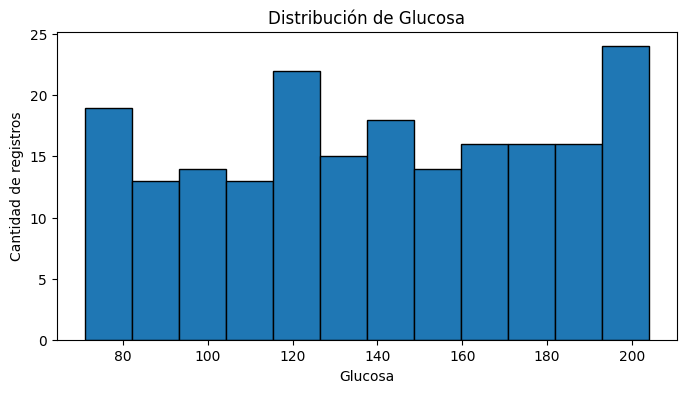

In [21]:
# RETO A: mayores de 60 años
mayores = df[df["Edad"] > 60]
print("Mayores de 60:",len(mayores))
display(mayores.head())

# RETO B: completa una nueva gráfica
# Cambia el nombre de la columna si deseas graficar otra variable
variable = "Glucosa"
plt.figure(figsize=(8,4))
plt.hist(df[variable],bins=12,edgecolor="black")
plt.title("Distribución de " + variable)
plt.xlabel(variable)
plt.ylabel("Cantidad de registros")
plt.show()